Файл успешно загружен!
Количество записей: 1134
Столбцы: ['date', 'message_id', 'reply_to_msg_id', 'channel_name', 'channel_id', 'sender', 'sender_id', 'message', 'views', 'comments', 'reactions', 'channel_members_count', 'channel_url', 'reactions_total', 'forwarded', 'forwards', 'topic_title']
Публикаций с текстом: 775

ТОП-5 ПО ПРОСМОТРАМ


,date,message,views,reactions_total
391,2025-11-01 06:55:22+00:00,🎁**РОЗЫГРЫШ DYSON В SODA — КРАСИВОЙ УКЛАДКОЙ М...,9605,312
405,2025-10-09 07:03:48+00:00,Это не просто ногти. Это эффект “вау” 😍при каж...,9467,39
48,2026-08-27 13:01:29+00:00,**Дарим два сертификата по 10000₽** Мы решил...,9463,1002
471,2025-05-28 11:51:57+00:00,**Розыгрыш для настоящих богинь лета**🎁** ** С...,8722,217
395,2025-10-21 13:06:10+00:00,🎁**ГРАНДИОЗНЫЙ КОНКУРС от Нового Радио и SODA ...,8221,227



ТОП-5 ПО РЕАКЦИЯМ


,date,message,views,reactions_total
48,2026-08-27 13:01:29+00:00,**Дарим два сертификата по 10000₽** Мы решил...,9463,1002
29,2026-11-01 15:49:11+00:00,вы всё ещё можете заказать наш совместный **Gi...,2680,806
270,2026-02-02 16:00:22+00:00,КОНКУРС **MASCÓTTE** x **Soda** Встречайте ...,5535,735
106,2026-06-15 14:20:18+00:00,**Добавьте ярких красок в это лето вместе с Wo...,5845,718
383,2025-11-06 14:26:28+00:00,"**Брови, которым позавидует даже ведьма 🕸️ ** ...",4906,713



РАСПРЕДЕЛЕНИЕ ПУБЛИКАЦИЙ
category
Услуги                               409
Другие публикации                    200
Розыгрыши                             44
Розыгрыши, Акции                      31
Акции                                 19
Акции, Услуги                         18
Новости                               18
Розыгрыши, Акции, Услуги              16
Услуги, Новости                       10
Розыгрыши, Услуги                      4
Акции, Услуги, Новости                 2
Розыгрыши, Акции, Новости              2
Розыгрыши, Акции, Услуги, Новости      1
Акции, Новости                         1
Name: count, dtype: int64

СРАВНЕНИЕ КАТЕГОРИЙ


,количество_постов,средние_просмотры,средние_реакции,средние_комментарии,средний_ER
category,,,,,
"Розыгрыши, Услуги",4,5433.00,245.50,0.00,4.32
"Розыгрыши, Акции, Услуги",16,5100.31,259.50,0.00,5.04
"Розыгрыши, Акции",31,4909.58,227.29,0.00,4.11
"Акции, Новости",1,4731.00,54.00,0.00,1.14
"Розыгрыши, Акции, Новости",2,4153.00,324.00,0.00,7.73
Розыгрыши,44,3916.32,62.41,0.07,1.49
"Розыгрыши, Акции, Услуги, Новости",1,3846.00,181.00,0.00,4.71
"Акции, Услуги",18,3756.50,43.94,1.39,1.05
Новости,18,3572.39,74.44,0.22,1.91


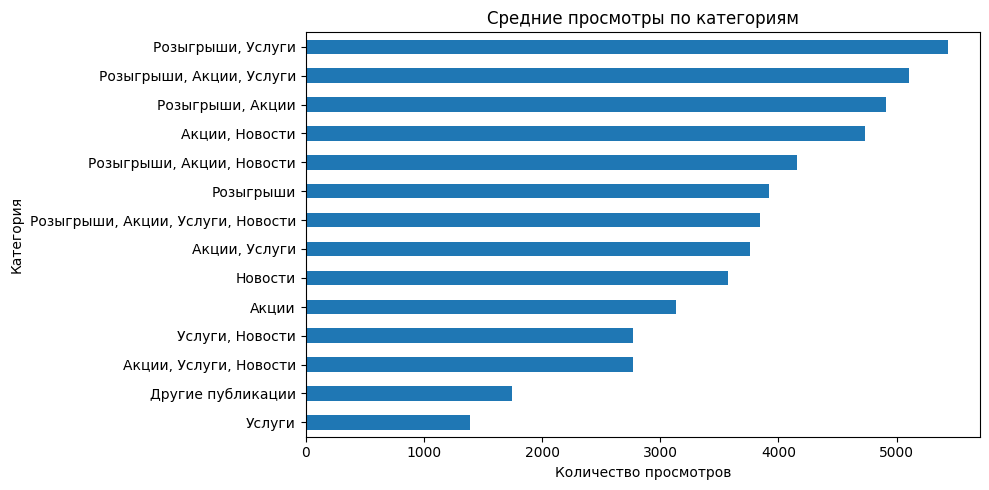

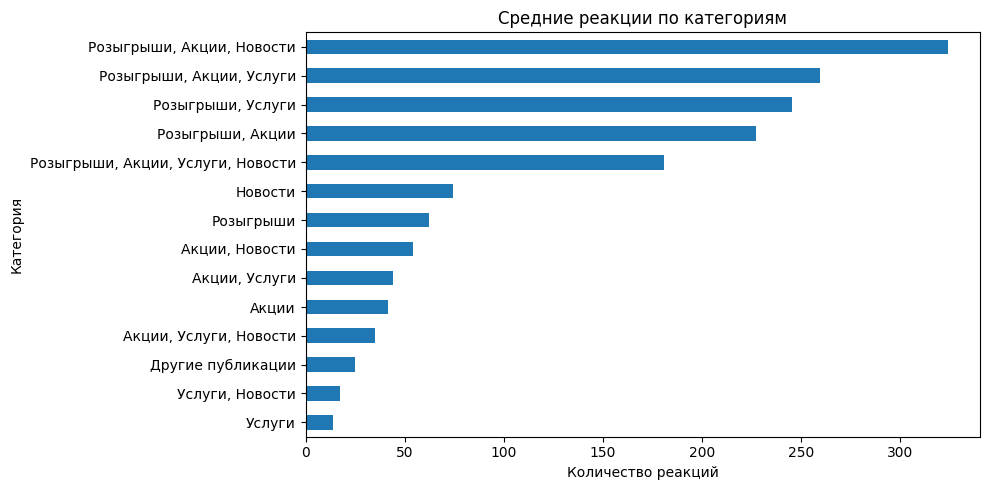

ValueError: Excel does not support datetimes with timezones. Please ensure that datetimes are timezone unaware before writing to Excel.

In [1]:

# ==========================================
# АНАЛИЗ TELEGRAM-КАНАЛА SODA
# ==========================================

!pip install pandas matplotlib openpyxl -q

import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.display import display

# 1. ЗАГРУЗКА CSV

file_path = "/content/Messages_Soda _ Сеть салонов красоты.csv"

df = pd.read_csv(
    file_path,
    sep=";",
    encoding="utf-8-sig"
)

print("Файл успешно загружен!")
print("Количество записей:", len(df))
print("Столбцы:", df.columns.tolist())


# 2. ПОДГОТОВКА ДАННЫХ

# Преобразуем показатели в числа
for col in ["views", "reactions_total", "comments", "forwards"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Преобразуем дату
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Убираем пустые сообщения и технические записи MediaMessage
df["message"] = df["message"].fillna("").astype(str)

# Оставляем только публикации с текстом
text_df = df[
    (df["message"].str.strip() != "") &
    (df["message"].str.strip() != "MediaMessage")
].copy()

print("Публикаций с текстом:", len(text_df))


# 3. ТОП-5 ПО ПРОСМОТРАМ

print("\nТОП-5 ПО ПРОСМОТРАМ")

top_views = text_df.sort_values(
    by="views",
    ascending=False
).head(5)

display(
    top_views[["date", "message", "views", "reactions_total"]]
)


# 4. ТОП-5 ПО РЕАКЦИЯМ

print("\nТОП-5 ПО РЕАКЦИЯМ")

top_reactions = text_df.sort_values(
    by="reactions_total",
    ascending=False
).head(5)

display(
    top_reactions[
        ["date", "message", "views", "reactions_total"]
    ]
)


# 5. КЛАССИФИКАЦИЯ ПУБЛИКАЦИЙ

# Ключевые слова для каждой категории

categories = {
    "Розыгрыши": [
        "розыгрыш", "разыгрываем", "победител",
        "конкурс", "подарим", "участвуй"
    ],

    "Акции": [
        "скидка", "акция", "специальное предложение",
        "промокод", "выгодно", "в подарок",
        "бесплатно", "сертификат"
    ],

    "Услуги": [
        "маникюр", "педикюр", "окрашивание",
        "стрижка", "брови", "ресницы",
        "укладка", "мастер", "процедура"
    ],

    "Новости": [
        "открытие", "открыли", "новый салон",
        "новости", "команда", "событие",
        "партнерство", "коллаборация"
    ]
}

def classify_post(message):

    message = message.lower()

    found_categories = []

    for category, keywords in categories.items():

        for word in keywords:

            if word in message:
                found_categories.append(category)
                break

    if found_categories:
        return ", ".join(found_categories)

    return "Другие публикации"


text_df["category"] = text_df["message"].apply(classify_post)

print("\nРАСПРЕДЕЛЕНИЕ ПУБЛИКАЦИЙ")

print(text_df["category"].value_counts())


# 6. СРАВНЕНИЕ ЭФФЕКТИВНОСТИ КАТЕГОРИЙ

# Рассчитываем вовлеченность:
# реакции / просмотры * 100

text_df["engagement_rate"] = (
    text_df["reactions_total"] /
    text_df["views"].replace(0, pd.NA)
) * 100

# Группируем публикации по категориям

stats = text_df.groupby("category").agg(
    количество_постов=("message", "count"),
    средние_просмотры=("views", "mean"),
    средние_реакции=("reactions_total", "mean"),
    средние_комментарии=("comments", "mean"),
    средний_ER=("engagement_rate", "mean")
).round(2)

print("\nСРАВНЕНИЕ КАТЕГОРИЙ")

display(stats.sort_values(
    by="средние_просмотры",
    ascending=False
))


# 7. ГРАФИК: СРЕДНИЕ ПРОСМОТРЫ

stats["средние_просмотры"].sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Средние просмотры по категориям"
)

plt.xlabel("Количество просмотров")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()


# 8. ГРАФИК: СРЕДНИЕ РЕАКЦИИ

stats["средние_реакции"].sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Средние реакции по категориям"
)

plt.xlabel("Количество реакций")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()


# 9. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ В EXCEL

with pd.ExcelWriter("SODA_analytics.xlsx") as writer:

    text_df.to_excel(
        writer,
        sheet_name="Все публикации",
        index=False
    )

    top_views.to_excel(
        writer,
        sheet_name="ТОП просмотров",
        index=False
    )

    top_reactions.to_excel(
        writer,
        sheet_name="ТОП реакций",
        index=False
    )

    stats.to_excel(
        writer,
        sheet_name="Сравнение категорий"
    )

print("\nАНАЛИЗ ЗАВЕРШЁН!")
print("Файл SODA_analytics.xlsx создан.")


Файл успешно загружен!
Количество публикаций: 1134
Количество столбцов: 17

Публикаций с текстом: 775

========== ОБЩАЯ СТАТИСТИКА ==========
Всего публикаций: 1134
Публикаций с текстом: 775
Среднее количество просмотров: 2361.6
Среднее количество реакций: 26.8
Максимальное количество просмотров: 9605
Максимальное количество реакций: 1002

========== ТОП-5 ПО ПРОСМОТРАМ ==========


,date,message,views,reactions_total
391,2025-11-01 06:55:22,🎁**РОЗЫГРЫШ DYSON В SODA — КРАСИВОЙ УКЛАДКОЙ М...,9605,312
405,2025-10-09 07:03:48,Это не просто ногти. Это эффект “вау” 😍при каж...,9467,39
48,2026-08-27 13:01:29,**Дарим два сертификата по 10000₽** Мы решил...,9463,1002
471,2025-05-28 11:51:57,**Розыгрыш для настоящих богинь лета**🎁** ** С...,8722,217
395,2025-10-21 13:06:10,🎁**ГРАНДИОЗНЫЙ КОНКУРС от Нового Радио и SODA ...,8221,227



========== ТОП-5 ПО РЕАКЦИЯМ ==========


,date,message,views,reactions_total
48,2026-08-27 13:01:29,**Дарим два сертификата по 10000₽** Мы решил...,9463,1002
29,2026-11-01 15:49:11,вы всё ещё можете заказать наш совместный **Gi...,2680,806
270,2026-02-02 16:00:22,КОНКУРС **MASCÓTTE** x **Soda** Встречайте ...,5535,735
106,2026-06-15 14:20:18,**Добавьте ярких красок в это лето вместе с Wo...,5845,718
383,2025-11-06 14:26:28,"**Брови, которым позавидует даже ведьма 🕸️ ** ...",4906,713



========== КАТЕГОРИИ ПУБЛИКАЦИЙ ==========


,message,category
8,"**У красоты и вина гораздо больше общего, чем ...",Акции
9,Результат розыгрыша Победили пользователи: [...,Розыгрыши
10,Сегодня команда стилистов Soda 🥤 выступает на ...,Новости
12,Продолжаем нашу серию преображений в рамках ко...,Акции
13,Бранч в @sharemoscow по случаю запуска коллабо...,Другие публикации
15,**Бахнуть каре или побриться налысо? Распакуйт...,Розыгрыши
16,Результат розыгрыша Победили пользователи: [...,Розыгрыши
23,[**Soda Artistic Team**](https://t.me/sodanail...,Услуги
29,вы всё ещё можете заказать наш совместный **Gi...,Другие публикации
30,🎃 **УЗНАЙТЕ СВОЮ ТЁМНУЮ СТОРОНУ И ПОЛУЧИТЕ ПОД...,Акции



========== ЭФФЕКТИВНОСТЬ КАТЕГОРИЙ ==========


,количество_публикаций,средние_просмотры,средние_реакции,средние_комментарии,средний_процент_реакций
category,,,,,
Розыгрыши,98,4489.84,160.77,0.06,3.18
Новости,18,3572.39,74.44,0.24,1.91
Акции,40,3436.72,42.70,1.03,1.03
Другие публикации,200,1748.12,24.84,0.03,0.89
Услуги,419,1420.71,13.95,0.00,0.48


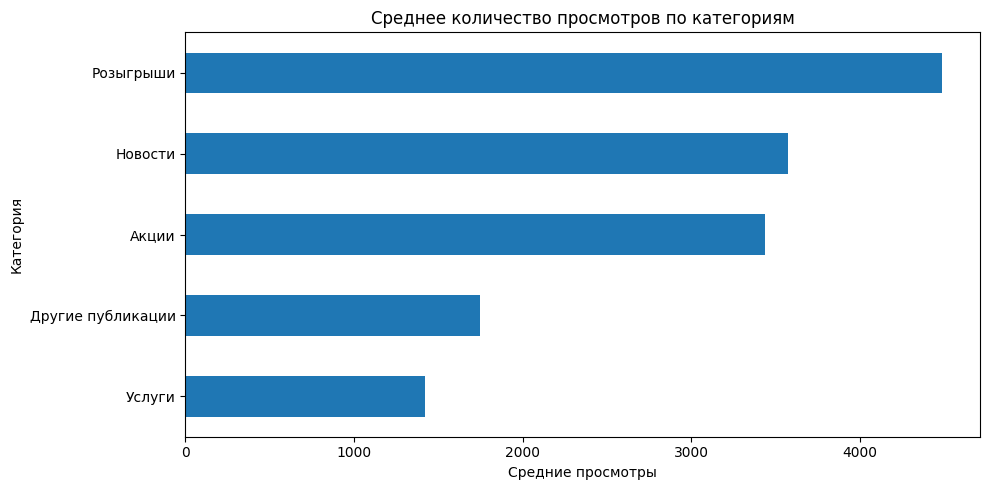

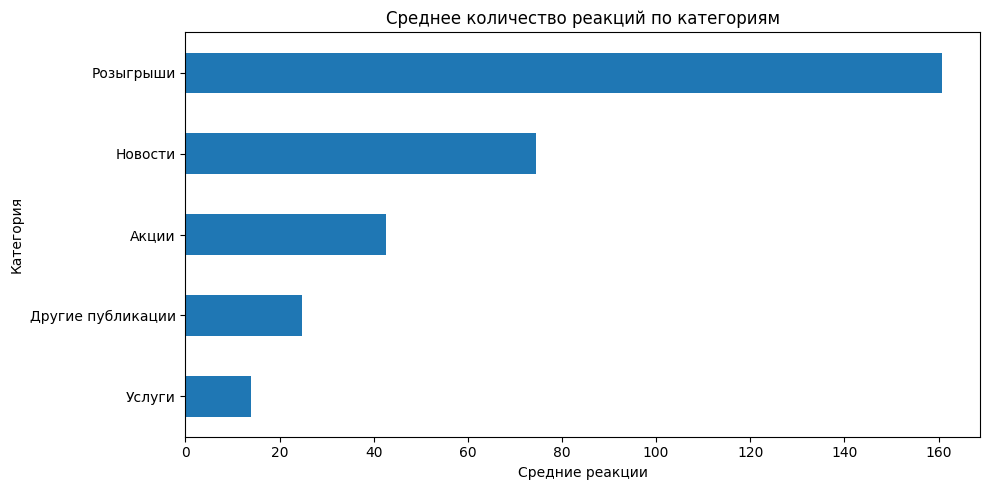

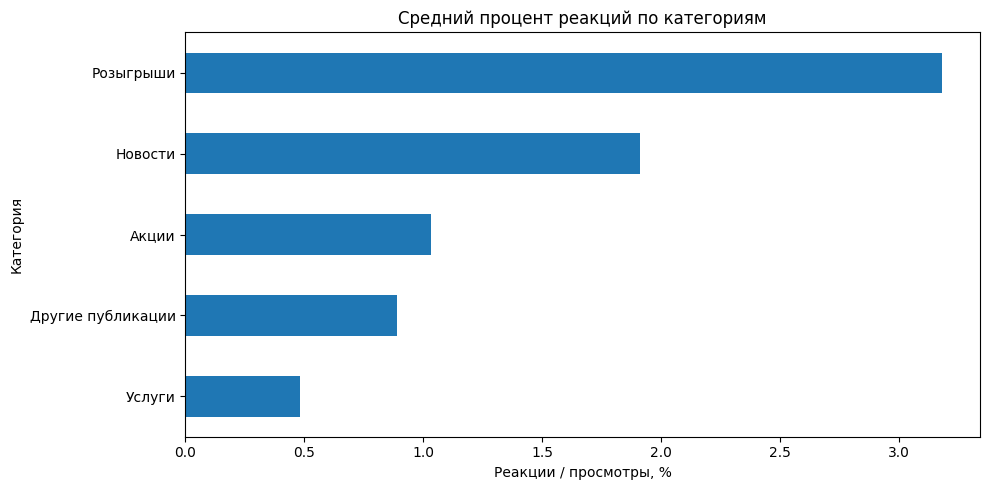


========== КРАТКИЕ ИТОГИ ==========
Лидер по средним просмотрам: Розыгрыши
Лидер по средним реакциям: Розыгрыши
Лидер по проценту реакций: Розыгрыши

АНАЛИЗ ЗАВЕРШЁН!


In [2]:

# ==========================================
# АНАЛИЗ TELEGRAM-КАНАЛА SODA
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. ЗАГРУЗКА ФАЙЛА
# ==========================================

file_path = "/content/Messages_Soda _ Сеть салонов красоты.csv"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded))

df = pd.read_csv(
    file_path,
    sep=";",
    encoding="utf-8-sig"
)

print("Файл успешно загружен!")
print("Количество публикаций:", len(df))
print("Количество столбцов:", len(df.columns))


# 2. ПОДГОТОВКА ДАННЫХ
# ==========================================

# Приводим даты к единому формату
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce",
    utc=True
)

# Убираем часовой пояс — он нам не понадобится
df["date"] = df["date"].dt.tz_localize(None)

# Преобразуем числовые показатели
numeric_columns = [
    "views",
    "reactions_total",
    "comments",
    "forwards"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Просмотры и реакции без значений считаем нулевыми
df["views"] = df["views"].fillna(0)
df["reactions_total"] = df["reactions_total"].fillna(0)

# Комментарии оставляем без заполнения пропусков:
# пустое значение не обязательно означает отсутствие комментариев

# Убираем строки, где вместо текста стоит MediaMessage
df["message"] = df["message"].fillna("").astype(str)

text_df = df[
    ~df["message"].str.contains("MediaMessage", case=False)
].copy()

print("\nПубликаций с текстом:", len(text_df))


# 3. ОБЩАЯ СТАТИСТИКА
# ==========================================

print("\n========== ОБЩАЯ СТАТИСТИКА ==========")

print("Всего публикаций:", len(df))
print("Публикаций с текстом:", len(text_df))
print("Среднее количество просмотров:",
      round(df["views"].mean(), 1))

print("Среднее количество реакций:",
      round(df["reactions_total"].mean(), 1))

print("Максимальное количество просмотров:",
      int(df["views"].max()))

print("Максимальное количество реакций:",
      int(df["reactions_total"].max()))


# 4. ТОП-5 ПУБЛИКАЦИЙ ПО ПРОСМОТРАМ
# ==========================================

top_views = text_df.sort_values(
    by="views",
    ascending=False
).head(5)

print("\n========== ТОП-5 ПО ПРОСМОТРАМ ==========")

display(
    top_views[["date", "message", "views", "reactions_total"]]
)


# 5. ТОП-5 ПУБЛИКАЦИЙ ПО РЕАКЦИЯМ
# ==========================================

top_reactions = text_df.sort_values(
    by="reactions_total",
    ascending=False
).head(5)

print("\n========== ТОП-5 ПО РЕАКЦИЯМ ==========")

display(
    top_reactions[["date", "message", "views", "reactions_total"]]
)


# 6. КЛАССИФИКАЦИЯ ПУБЛИКАЦИЙ
# ==========================================

def classify_post(message):
    message = message.lower()

    categories = {
        "Розыгрыши": [
            "розыгрыш", "разыгрываем", "победител",
            "конкурс", "подарим", "участвуй"
        ],

        "Акции": [
            "скидка", "акция", "специальное предложение",
            "промокод", "выгодно", "в подарок",
            "бесплатно", "сертификат"
        ],

        "Услуги": [
            "маникюр", "педикюр", "окрашивание",
            "стрижка", "брови", "ресницы",
            "укладка", "мастер", "процедура"
        ],

        "Новости": [
            "открытие", "открыли", "новый салон",
            "новости", "команда", "событие",
            "партнерство", "коллаборация"
        ]
    }

    # Каждой публикации присваиваем одну основную категорию
    for category, keywords in categories.items():
        if any(word in message for word in keywords):
            return category

    return "Другие публикации"


text_df["category"] = text_df["message"].apply(classify_post)

print("\n========== КАТЕГОРИИ ПУБЛИКАЦИЙ ==========")

display(
    text_df[["message", "category"]].head(10)
)


# 7. СРАВНЕНИЕ ЭФФЕКТИВНОСТИ КАТЕГОРИЙ
# ==========================================

text_df["engagement_rate"] = (
    text_df["reactions_total"]
    / text_df["views"].replace(0, pd.NA)
) * 100

category_stats = text_df.groupby("category").agg(
    количество_публикаций=("message", "count"),
    средние_просмотры=("views", "mean"),
    средние_реакции=("reactions_total", "mean"),
    средние_комментарии=("comments", "mean"),
    средний_процент_реакций=("engagement_rate", "mean")
).round(2)

category_stats = category_stats.sort_values(
    by="средние_просмотры",
    ascending=False
)

print("\n========== ЭФФЕКТИВНОСТЬ КАТЕГОРИЙ ==========")

display(category_stats)


# 8. ГРАФИК: СРЕДНИЕ ПРОСМОТРЫ ПО КАТЕГОРИЯМ
# ==========================================

plt.figure(figsize=(10, 5))

category_stats["средние_просмотры"].sort_values().plot(
    kind="barh"
)

plt.title("Среднее количество просмотров по категориям")
plt.xlabel("Средние просмотры")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()


# 9. ГРАФИК: СРЕДНИЕ РЕАКЦИИ ПО КАТЕГОРИЯМ
# ==========================================

plt.figure(figsize=(10, 5))

category_stats["средние_реакции"].sort_values().plot(
    kind="barh"
)

plt.title("Среднее количество реакций по категориям")
plt.xlabel("Средние реакции")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()


# 10. ГРАФИК: ВОВЛЕЧЁННОСТЬ ПО КАТЕГОРИЯМ
# ==========================================

plt.figure(figsize=(10, 5))

category_stats["средний_процент_реакций"].sort_values().plot(
    kind="barh"
)

plt.title("Средний процент реакций по категориям")
plt.xlabel("Реакции / просмотры, %")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()


# 11. ИТОГИ
# ==========================================

print("\n========== КРАТКИЕ ИТОГИ ==========")

best_views = category_stats["средние_просмотры"].idxmax()
best_reactions = category_stats["средние_реакции"].idxmax()
best_engagement = category_stats[
    "средний_процент_реакций"
].idxmax()

print("Лидер по средним просмотрам:", best_views)
print("Лидер по средним реакциям:", best_reactions)
print("Лидер по проценту реакций:", best_engagement)

print("\nАНАЛИЗ ЗАВЕРШЁН!")
